# Indirect methods in pykep

Indirect methods turn an optimal-control problem into a boundary-value problem: guess the missing initial costates and final time, integrate once, and drive the terminal errors to zero. This is a root-finding problem, not an optimization problem in disguise.

For smooth, square shooting systems, {py:func}`scipy.optimize.root` with `method="hybr"`, MINPACK's modified Powell hybrid method, is an excellent first choice. It is not a universal winner: scaling, initial guesses, singular arcs and the problem itself still matter. Shooting can be sensitive enough to make a good initial guess feel like a superpower.

The [Pontryagin notebook](./pontryagin_equinoctial_time.ipynb) packages the shooting equations as a [pygmo](https://esa.github.io/pygmo2/) UDP and wraps MINPACK in a pygmo UDA because one of its goals is a single-thread algorithmic comparison, including IPOPT. For ordinary single-problem solves, call SciPy directly on the shooting function: this avoids pygmo wrapper overhead and is generally faster, although timings depend on the problem.

In [1]:
import numpy as np
import heyoka as hy
import pykep as pk
from scipy.optimize import root
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection

## 1 - Manual construction of the TPBVP

We minimize transfer time between two fixed orbital states under central gravity and bounded low thrust. The final time and final mass are free. We consider **normal extremals only**, normalize the objective multiplier to one, and use the minimum-Hamiltonian convention. Abnormal extremals are not represented here.

Let $\mathbf x=(p,f,g,h,k,L)$ be the prograde modified equinoctial elements ([definitions](../elements.rst)), $m$ the mass, $u\in[0,1]$ the throttle, and $\mathbf i$ the unit thrust direction in the radial-transverse-normal frame. With $c_1=T_{\max}$ and $c_2=I_{sp}g_0$, the equations are

$$
\dot{\mathbf x}=\frac{c_1u}{m}\mathbf B(\mathbf x)\mathbf i+\mathbf D(\mathbf x),\qquad
\dot m=-\frac{c_1}{c_2}u.
$$

Writing $w=1+f\cos L+g\sin L$ and $s^2=1+h^2+k^2$, the coefficients are

$$
\mathbf B=\sqrt{\frac{p}{\mu}}
\begin{bmatrix}
0 & 2p/w & 0 \\
\sin L & ((1+w)\cos L+f)/w & -g(h\sin L-k\cos L)/w \\
-\cos L & ((1+w)\sin L+g)/w & f(h\sin L-k\cos L)/w \\
0 & 0 & s^2\cos L/(2w) \\
0 & 0 & s^2\sin L/(2w) \\
0 & 0 & (h\sin L-k\cos L)/w
\end{bmatrix},\qquad
$$
$$
\mathbf D=\begin{bmatrix}0&0&0&0&0&\sqrt{\mu/p^3}\,w^2\end{bmatrix}^{T}.
$$

We construct the equations symbolically with [heyoka.py](https://bluescarni.github.io/heyoka.py/), which `pykep` uses for its Taylor integrators.

In [2]:
# State variables
p, f, g, h, k, L, m = hy.make_vars("p", "f", "g", "h", "k", "L", "m")
# Costate variables
lp, lf, lg, lh, lk, lL, lm = hy.make_vars(
    "lp", "lf", "lg", "lh", "lk", "lL", "lm"
)
# Control variables: throttle and RTN thrust direction
u, i_r, i_t, i_n = hy.make_vars("u", "ir", "it", "in")

To keep the derivation readable, we define compact expressions and vectorized groupings.

In [3]:
# Reusable scalar expressions
w = 1 + f * hy.cos(L) + g * hy.sin(L)
s2 = 1 + h * h + k * k
B = np.array(
    [
        [0, 2 * p / w, 0.0],
        [
            hy.sin(L),
            ((1 + w) * hy.cos(L) + f) / w,
            -g / w * (h * hy.sin(L) - k * hy.cos(L)),
        ],
        [
            -hy.cos(L),
            ((1 + w) * hy.sin(L) + g) / w,
            f / w * (h * hy.sin(L) - k * hy.cos(L)),
        ],
        [0, 0, s2 / w / 2.0 * hy.cos(L)],
        [0, 0, s2 / w / 2.0 * hy.sin(L)],
        [0, 0, 1.0 / w * (h * hy.sin(L) - k * hy.cos(L))],
    ]
) * hy.sqrt(p / hy.par[0])

D = np.array([0.0, 0.0, 0.0, 0.0, 0.0, hy.sqrt(hy.par[0] / p / p / p) * w * w])

i_vers = np.array([i_r, i_t, i_n])
lx = np.array([lp, lf, lg, lh, lk, lL])

The dynamics can then be written as:

In [4]:
# Dynamics
fx = np.dot(B, i_vers) * u * hy.par[1] / m + D
fm = - hy.par[1] / hy.par[2] * u

With costates $\boldsymbol\lambda_x$ and $\lambda_m$, the normal Hamiltonian is

$$
H=1+\boldsymbol\lambda_x\cdot\dot{\mathbf x}+\lambda_m\dot m.
$$

Its additive $1$ fixes the normal multiplier. Do not remove it when imposing the free-time condition: $H(t_f)=0$.

In [5]:
H_full = lx @ fx + lm * fm + 1.0
BTlam = B.T @ lx
BTlam_norm = hy.sqrt(BTlam @ BTlam)

The [heyoka.py](https://bluescarni.github.io/heyoka.py/) parameters are $[\mu,c_1,c_2]$. We will nondimensionalize all quantities before integrating.

For the full state $\mathbf q=(\mathbf x,m)$ and costate $\boldsymbol\lambda=(\boldsymbol\lambda_x,\lambda_m)$, Hamilton's equations are

$$
\dot{\mathbf q}=\frac{\partial H}{\partial\boldsymbol\lambda},\qquad
\dot{\boldsymbol\lambda}=-\frac{\partial H}{\partial\mathbf q}.
$$

Differentiate before substituting the minimizing control.

In [6]:
# Augmented equations of motion
rhs = [
    hy.diff(H_full, var)
    for var in [lp, lf, lg, lh, lk, lL, lm, p, f, g, h, k, L, m]
]
for j in range(7, 14):
    rhs[j] = -rhs[j]

Minimizing over the thrust direction gives $\mathbf i^*=-\mathbf B^T\boldsymbol\lambda_x/\|\mathbf B^T\boldsymbol\lambda_x\|$ when the denominator is nonzero. The throttle coefficient is $-c_1(\|\mathbf B^T\boldsymbol\lambda_x\|/m+\lambda_m/c_2)$. Since $\lambda_m(t_f)=0$ and $\dot\lambda_m=-c_1u\|\mathbf B^T\boldsymbol\lambda_x\|/m^2\leq 0$, it is nonpositive along an extremal: full throttle is a minimizer. Singular cases require separate treatment.

In [7]:
argmin_H_full = {
    i_r: -BTlam[0] / BTlam_norm,
    i_t: -BTlam[1] / BTlam_norm,
    i_n: -BTlam[2] / BTlam_norm,
    u: hy.expression(1.0),
}

Substitution closes the augmented dynamics in $(\mathbf q,\boldsymbol\lambda)$.

In [8]:
rhs = hy.subs(rhs, argmin_H_full)

# We also build the Hamiltonian as a function of the state / co-state only
# (i.e. no longer of controls now solved thanks to the minimum principle)
H = hy.subs(H_full, argmin_H_full)

We compile the minimized Hamiltonian, its gradient, and the closed dynamics. The {py:func}`~heyoka.taylor_adaptive` integrator propagates the {py:class}`~heyoka.var_ode_sys` derivatives with respect to the seven initial costates.

In [9]:
full_state = [p, f, g, h, k, L, m, lp, lf, lg, lh, lk, lL, lm]
H_func = hy.cfunc([H], full_state)
H_grad = hy.cfunc([hy.diff(H, var) for var in full_state], full_state)
dyn_func = hy.cfunc(rhs, full_state)
sys = list(zip(full_state, rhs))
ta = hy.taylor_adaptive(sys, state=[1.0] * 14, tol=1e-12, compact_mode=True)

In [10]:
var_sys = hy.var_ode_sys(sys, args=[lp, lf, lg, lh, lk, lL, lm])
ta_var = hy.taylor_adaptive(var_sys, tol=1e-12, compact_mode=True)
ic_var = ta_var.state[14:].copy()

## 2 - Shooting function and its gradient

We use Earth's state at MJD2000 400 and a **fixed** target state sampled from Mars 255.702802384 days later. The target does not move when the solver changes the flight time: this is a fixed-endpoint example, not a general moving-planet rendezvous. Its longitude is unwrapped onto the chosen zero-revolution branch.

Lengths are scaled by one AU, mass by the initial mass, and time by $\sqrt{\mathrm{AU}^3/\mu_{\odot}}$ (about 58 days, not one year). The costates and time below are in these nondimensional units.

In [11]:
source = pk.planet(pk.udpla.jpl_lp("earth"))
target = pk.planet(pk.udpla.jpl_lp("mars"))
t0 = pk.epoch(400)
target_epoch = t0 + 255.70280238443087

length_unit = pk.AU
mass_unit = 1500.0
time_unit = np.sqrt(length_unit**3 / pk.MU_SUN)
velocity_unit = length_unit / time_unit
acceleration_unit = velocity_unit / time_unit
mu = 1.0
c1 = 0.6 / (mass_unit * acceleration_unit)
c2 = 3000.0 * pk.G0 / velocity_unit
m0 = 1.0

eq0 = np.asarray(pk.ic2mee(source.eph(t0), pk.MU_SUN), dtype=float)
eqf = np.asarray(pk.ic2mee(target.eph(target_epoch), pk.MU_SUN), dtype=float)
eq0[0] /= length_unit
eqf[0] /= length_unit
if eqf[5] < eq0[5]:
    eqf[5] += 2.0 * np.pi

pars = [mu, c1, c2]
ta.pars[:] = pars
ta_var.pars[:] = pars

In [12]:
def shooting_function(guess):
    ta.time = 0.0
    ta.state[:6] = eq0
    ta.state[6] = m0
    ta.state[7:14] = guess[:7]
    ta.propagate_until(guess[7])
    return np.r_[ta.state[:6] - eqf, ta.state[13], H_func(ta.state, pars=pars)[0]]

The eight unknowns are $\mathbf z=(\boldsymbol\lambda_x(0),\lambda_m(0),t_f)$. Their eight residuals are

$$
\mathbf F(\mathbf z)=\begin{bmatrix}
\mathbf x(t_f)-\mathbf x_f \\
\lambda_m(t_f) \\
H(t_f)
\end{bmatrix}=\mathbf 0.
$$

The first six fix the terminal orbit state, the seventh comes from free final mass, and the last from free final time with a fixed terminal state. These mutable integrators are reused, so these functions are not thread-safe.

For $\mathbf y=(\mathbf x,m,\boldsymbol\lambda_x,\lambda_m)$, let $S=\partial\mathbf y(t_f)/\partial\boldsymbol\lambda(0)$. The variational equations supply $S$; the final-time derivative is $\dot{\mathbf y}(t_f)$. Thus the last Jacobian row is $\nabla H\,[S\;\dot{\mathbf y}]$. For this autonomous problem its last entry is zero analytically, but computing it also makes the chain rule visible.

The final time is measured from departure, not an absolute epoch. A moving target would add its own time derivative to the terminal-state residuals and modify the free-time transversality condition.

In [13]:
def shooting_jacobian(guess):
    ta_var.time = 0.0
    ta_var.state[:6] = eq0
    ta_var.state[6] = m0
    ta_var.state[7:14] = guess[:7]
    ta_var.state[14:] = ic_var
    ta_var.propagate_until(guess[7])
    final_state = ta_var.state[:14]
    sensitivities = np.vstack([
        ta_var.state[ta_var.get_vslice(order=1, component=index)]
        for index in range(14)
    ])
    flow = dyn_func(final_state, pars=pars)
    terminal_derivatives = np.column_stack((sensitivities, flow))
    return np.vstack((
        terminal_derivatives[:6],
        terminal_derivatives[13],
        H_grad(final_state, pars=pars) @ terminal_derivatives,
    ))

A central finite-difference check catches ordering mistakes before the solver has a chance to become mysterious.

In [14]:
rng = np.random.default_rng(42)
guess = np.r_[rng.uniform(-1, 1, 6), rng.uniform(0, 1), 250 * pk.DAY2SEC / time_unit]
step = 1e-6
basis = np.eye(8)
finite_difference = np.column_stack([
    (shooting_function(guess + step * direction) - shooting_function(guess - step * direction)) / (2 * step)
    for direction in basis
])
np.testing.assert_allclose(shooting_jacobian(guess), finite_difference, rtol=2e-5, atol=2e-7)
print("Maximum Jacobian difference:", np.max(np.abs(shooting_jacobian(guess) - finite_difference)))

Maximum Jacobian difference: 4.08109046557e-09


## 3 - Solving the problem in single shooting

The fixed random seed gives a reproducible starting point; it is not a promise that an arbitrary guess will converge. `factor` controls MINPACK's initial step bound. Always inspect the residual and physical solution, not just the solver's status message. A root is a candidate extremal, not by itself a proof of global optimality.

In [15]:
result = root(
    shooting_function,
    guess,
    jac=shooting_jacobian,
    method="hybr",
    tol=1e-10,
    options={"factor": 1.0},
)
residual = shooting_function(result.x)
residual_norm = np.linalg.norm(residual)
if not result.success or residual_norm > 1e-8 or result.x[7] <= 0 or ta.state[6] <= 0:
    raise RuntimeError(f"Shooting did not converge to a physical solution: {result.message}; residual={residual_norm:.3e}")

print(f"Flight time: {result.x[7] * time_unit * pk.SEC2DAY:.3f} days")
print(f"Final mass: {ta.state[6] * mass_unit:.3f} kg")
print(f"Residual norm: {residual_norm:.3e}")

Flight time: 255.703 days
Final mass: 1049.434 kg
Residual norm: 2.644e-12


## 4 - Make a plot

We propagate the converged extremal again and make a plot of the trajectory. The `pykep` functions {py:func}`~pykep.plot.make_3Daxis`, {py:func}`~pykep.plot.add_sun`, {py:func}`~pykep.plot.add_planet_orbit` and {py:func}`~pykep.plot.add_planet` set the scene.

In [16]:
times = np.linspace(0.0, result.x[7], 500)
ta.time = 0.0
ta.state[:6] = eq0
ta.state[6] = m0
ta.state[7:14] = result.x[:7]
states = ta.propagate_grid(times)[-1]
trajectory = np.array([pk.mee2ic(state[:6], mu)[0] for state in states])
days = times * time_unit * pk.SEC2DAY
earth_path = np.array([source.eph(t0 + day)[0] for day in days]) / length_unit
mars_path = np.array([target.eph(t0 + day)[0] for day in days]) / length_unit

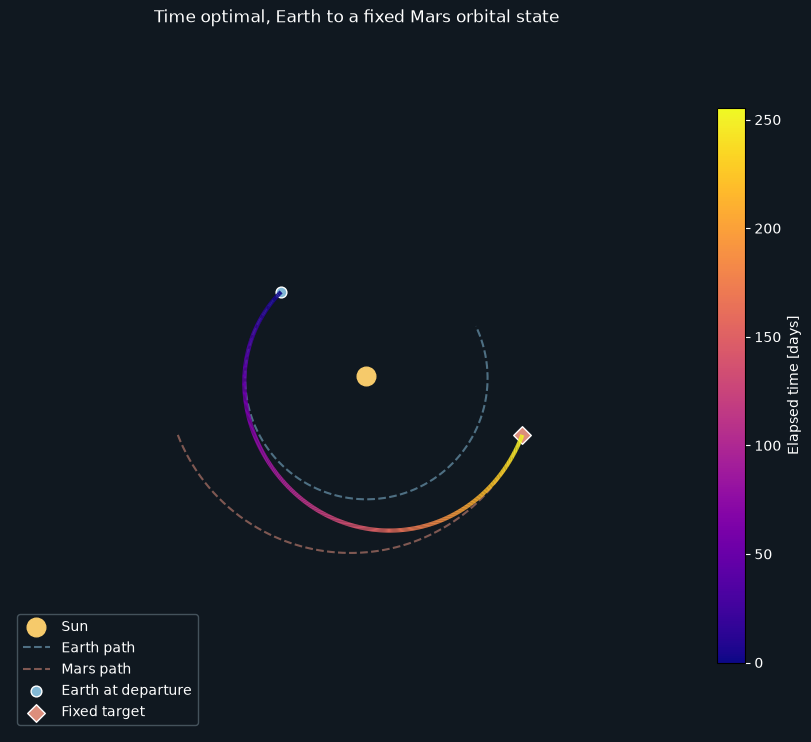

In [17]:
from mpl_toolkits.mplot3d.art3d import Line3DCollection

# Plot the Sun, and planets
ax = pk.plot.make_3Daxis(figsize=(8, 8), layout="constrained")
fig = ax.figure
fig.patch.set_facecolor("#101820")
ax.set_facecolor("#101820")
plot_range = [t0.mjd2000, (t0 + days[-1]).mjd2000]

pk.plot.add_sun(ax, s=180, c="#f6ca6b", label="Sun")
pk.plot.add_planet_orbit(ax, source, plot_range=plot_range, N=300, units=length_unit,
                         color="#82b8d5", linestyle="--", alpha=0.55, label="Earth path")
pk.plot.add_planet_orbit(ax, target, plot_range=plot_range, N=300, units=length_unit,
                         color="#dc8e7c", linestyle="--", alpha=0.55, label="Mars path")
pk.plot.add_planet(ax, source, when=t0, units=length_unit, s=60, c="#82b8d5",
                   edgecolors="white", label="Earth at departure")
pk.plot.add_planet(ax, target, when=target_epoch, units=length_unit, s=80, c="#dc8e7c",
                   marker="D", edgecolors="white", label="Fixed target")

# Plot the trajectory of the spacecraft
segments_3d = np.stack((trajectory[:-1], trajectory[1:]), axis=1)
track_3d = Line3DCollection(segments_3d, cmap="plasma", linewidth=3.0)
track_3d.set_array(days[:-1])
ax.add_collection3d(track_3d)

# Set the plot limits and view angle
ax.set_xlim(-1.7, 1.7)
ax.set_ylim(-1.7, 1.7)
ax.set_zlim(-1.7, 1.7)
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=90, azim=-90)
ax.set_axis_off()
ax.set_title("Time optimal, Earth to a fixed Mars orbital state", color="white", pad=12)
ax.legend(facecolor="#101820", edgecolor="#52616a", labelcolor="white", loc="lower left")
colorbar = fig.colorbar(track_3d, ax=ax, shrink=0.7, pad=0.02, label="Elapsed time [days]")
colorbar.ax.yaxis.label.set_color("white")
colorbar.ax.tick_params(colors="white")
plt.show()